# Семинар 9. Бросок на заданную дальность

Весь семинар — за ноутбуком, около 30 минут. Решаем задачу 1 из введения лекции: мяч должен упасть на расстоянии $D=30$ м, скорость броска — наименьшая.

| Мин | Шаг |
|---|---|
| 6 | **1. Без воздуха руками.** Система введения: ответ $45^\circ$ |
| 8 | **2. Свой метод Ньютона–Лагранжа** на той же системе |
| 10 | **3. С сопротивлением воздуха.** Полёт считает программа; сверка с IPOPT |
| 6 | **4. Угол и скорость** при разном сопротивлении |

Конспект: [`lecture09.md`](lecture09.md). Установка: `uv sync --group casadi` в корне репозитория; в Colab первая ячейка поставит CasADi сама.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

import numpy as np
import casadi as ca
import matplotlib.pyplot as plt
from l9helpers import *          # newton_lagrange, casadi_kkt, lam_ls, палитра (лекция 9)

D = 30.0                         # дальность, м
print("CasADi", ca.__version__)

CasADi 3.8.0


## Шаг 1. Без воздуха руками (6 мин)

**Главная мысль.** Пять уравнений введения решаются руками, и ответ — бросок под $45^\circ$.

Переменные — $x=(v_1,v_2,T)\in\mathbb R^3$: скорости по горизонтали и вертикали и время полёта. Система введения:

$$
\begin{aligned}
v_1&=\lambda_1T, & v_2&=\lambda_2T, & 0&=\lambda_1v_1+\lambda_2\,(v_2-9.81\,T),\\
v_1T&=D, & v_2T&=4.905\,T^2 .
\end{aligned}
$$

Решим её по шагам:

- из последнего уравнения $v_2=4.905\,T$, а из второго $v_2=\lambda_2T$; значит, $\lambda_2=4.905$;
- подставим $v_1=\lambda_1T$ и $v_2=\lambda_2T$ в третье уравнение: $\lambda_1^2+\lambda_2^2=9.81\,\lambda_2$, откуда $\lambda_1=4.905$;
- множители равны, поэтому $v_1=v_2$ — бросок под $45^\circ$;
- из $v_1T=D$ и $v_1=4.905\,T$ получаем $T=\sqrt{D/4.905}$.

**Что делает ячейка.** Считает ответ по этим формулам и проверяет все пять уравнений.

In [2]:
T1 = np.sqrt(D / 4.905)                                      # время полёта
v1 = v2 = 4.905 * T1                                         # v = lambda T, lambda = 4.905
lam_hand = np.array([4.905, 4.905])
x_hand = np.array([v1, v2, T1])
res = [v1 - 4.905 * T1, v2 - 4.905 * T1, 4.905 * v1 + 4.905 * (v2 - 9.81 * T1), v1 * T1 - D, v2 * T1 - 4.905 * T1**2]
assert np.allclose(res, 0)
print(f"v = ({v1:.3f}, {v2:.3f}) м/с, T = {T1:.3f} с, скорость {np.hypot(v1, v2):.3f} м/с = sqrt(9.81 D) = {np.sqrt(9.81 * D):.3f}")

v = (12.131, 12.131) м/с, T = 2.473 с, скорость 17.155 м/с = sqrt(9.81 D) = 17.155


**Что видим.** Скорость $17.16$ м/с, время полёта $2.47$ с. Скорость равна $\sqrt{9.81D}$ — школьная формула дальности при $45^\circ$.

## Шаг 2. Свой метод Ньютона–Лагранжа (8 мин)

**Главная мысль.** Метод не знает, что ответ можно найти руками. Ему нужны только $f$, $g$ и их производные.

**Что делает ячейка.** Записывает задачу в CasADi: $f$ и два ограничения. Функция `casadi_kkt` даёт $\nabla f$, $J$, $H$ и $g$ — производные считает CasADi (лекция 7). Метод `newton_lagrange` — тот же, что на цепи в лекции. Старт: $v=(10,\ 10)$, $T=2$, множители по МНК.

In [3]:
x = ca.SX.sym("x", 3)                                        # x = (v1, v2, T)
v1s, v2s, Ts = x[0], x[1], x[2]
f = 0.5 * (v1s**2 + v2s**2)                                  # половина квадрата скорости
g = ca.vertcat(v1s * Ts - D,                                 # g1: долетели до D
               v2s * Ts - 4.905 * Ts**2)                     # g2: вернулись на землю
kkt = casadi_kkt(x, f, g)

x0 = np.array([10.0, 10.0, 2.0])
hist = newton_lagrange(kkt, x0, lam_ls(kkt, x0, 2))
for k, (xk, lk, nF) in enumerate(hist):
    print(f"k = {k}: v = ({xk[0]:7.3f}, {xk[1]:7.3f}), T = {xk[2]:.3f}, lambda = ({lk[0]:.3f}, {lk[1]:.3f}), |F| = {nF:.1e}")
assert np.allclose(hist[-1][0], x_hand) and np.allclose(hist[-1][1], lam_hand) and len(hist) - 1 == 4

k = 0: v = ( 10.000,  10.000), T = 2.000, lambda = (4.903, 5.093), |F| = 1.0e+01
k = 1: v = ( 12.383,  12.327), T = 2.523, lambda = (4.908, 4.831), |F| = 1.5e+00
k = 2: v = ( 12.133,  12.132), T = 2.474, lambda = (4.905, 4.903), |F| = 2.6e-02
k = 3: v = ( 12.131,  12.131), T = 2.473, lambda = (4.905, 4.905), |F| = 6.9e-06
k = 4: v = ( 12.131,  12.131), T = 2.473, lambda = (4.905, 4.905), |F| = 1.8e-13


**Что видим.** Четыре итерации — и ответ шага 1, вместе с множителями $4.905$. Невязка падает с обрывом, как на окружности и цепи в лекции.

## Шаг 3. С сопротивлением воздуха (10 мин)

**Главная мысль.** Формулы полёта больше нет: точку падения считает программа. Метод тот же — меняются только $g$ и её производные.

Сопротивление пропорционально квадрату скорости. Уравнения движения мяча, $(s_1,s_2)$ — его положение:

$$
\ddot s_1=-c\,\lVert\dot s\rVert\,\dot s_1,\qquad \ddot s_2=-9.81-c\,\lVert\dot s\rVert\,\dot s_2 .
$$

Здесь $c=0.02$ 1/м — примерно как у теннисного мяча. Функция `flight` интегрирует их методом Рунге–Кутты (RK4) за 100 шагов по времени от $0$ до $T$. Ограничения: $g_1=s_1(T)-D$ и $g_2=s_2(T)$.

**Предскажите до запуска.** Угол броска — больше или меньше $45^\circ$? Скорость — больше или меньше $17.16$ м/с?

**Что делает ячейка.** Строит ограничения через `flight` и решает задачу тем же методом. Старт — ответ без воздуха. Затем та же задача в IPOPT; его множители `lam_g` — с обратным знаком (лекция 8, §6).

In [4]:
def flight(v1, v2, T, c, steps=100):
    """Положение мяча (s1, s2) в момент T: RK4 по уравнениям движения с сопротивлением c."""
    s = ca.vertcat(0, 0, v1, v2)                             # (s1, s2, скорость по s1, скорость по s2)
    h = T / steps                                            # шаг по времени

    def rhs(s):
        speed = ca.sqrt(s[2]**2 + s[3]**2)                   # модуль скорости
        return ca.vertcat(s[2], s[3], -c * speed * s[2], -9.81 - c * speed * s[3])

    for _ in range(steps):                                   # RK4: четыре оценки наклона на шаг
        k1 = rhs(s); k2 = rhs(s + h / 2 * k1); k3 = rhs(s + h / 2 * k2); k4 = rhs(s + h * k3)
        s = s + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return s[0], s[1]


def solve_throw(c, x_start, lam_start):
    """Бросок при сопротивлении c: свой метод и IPOPT. Возвращает (x, lambda, итераций, x IPOPT, lambda IPOPT)."""
    s1, s2 = flight(v1s, v2s, Ts, c)
    g = ca.vertcat(s1 - D, s2)                               # g1: долетели до D; g2: на земле
    h = newton_lagrange(casadi_kkt(x, f, g), x_start, lam_start)
    ip = ca.nlpsol("ip", "ipopt", {"x": x, "f": f, "g": g}, {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes"})
    sol = ip(x0=x_start, lbg=0, ubg=0)                       # lbg = ubg = 0: равенства
    return h[-1][0], h[-1][1], len(h) - 1, np.array(sol["x"]).ravel(), -np.array(sol["lam_g"]).ravel()

xc, lc, its, x_ip, l_ip = solve_throw(0.02, x_hand, lam_hand)
angle, speed = np.degrees(np.arctan2(xc[1], xc[0])), np.hypot(xc[0], xc[1])
print(f"наш метод: {its} итераций, v = ({xc[0]:.3f}, {xc[1]:.3f}), T = {xc[2]:.3f}, угол {angle:.2f}°, скорость {speed:.2f} м/с")
print(f"IPOPT:     v = ({x_ip[0]:.3f}, {x_ip[1]:.3f}), T = {x_ip[2]:.3f}; lambda наш {lc.round(3)}, IPOPT {l_ip.round(3)}")
assert np.allclose(xc, x_ip, atol=1e-6) and np.allclose(lc, l_ip, atol=1e-5)
assert np.isclose(angle, 40.93, atol=0.01) and np.isclose(speed, 22.34, atol=0.01)

наш метод: 5 итераций, v = (16.875, 14.633), T = 2.554, угол 40.93°, скорость 22.34 м/с
IPOPT:     v = (16.875, 14.633), T = 2.554; lambda наш [13.196  9.822], IPOPT [13.196  9.822]


**Что видим.** Угол $40.9^\circ$ — меньше $45^\circ$, скорость $22.3$ м/с — больше. Воздух тормозит мяч, и бросать выгоднее более полого: время полёта короче, сопротивление действует меньше. Наш метод и IPOPT дают одну точку и одни множители.

## Шаг 4. Угол и скорость при разном сопротивлении (6 мин)

**Что делает ячейка.** Решает задачу при $c$ от $0$ до $0.05$. Старт для каждого $c$ — ответ при предыдущем $c$. Слева — траектории при трёх $c$, справа — угол и скорость от $c$.

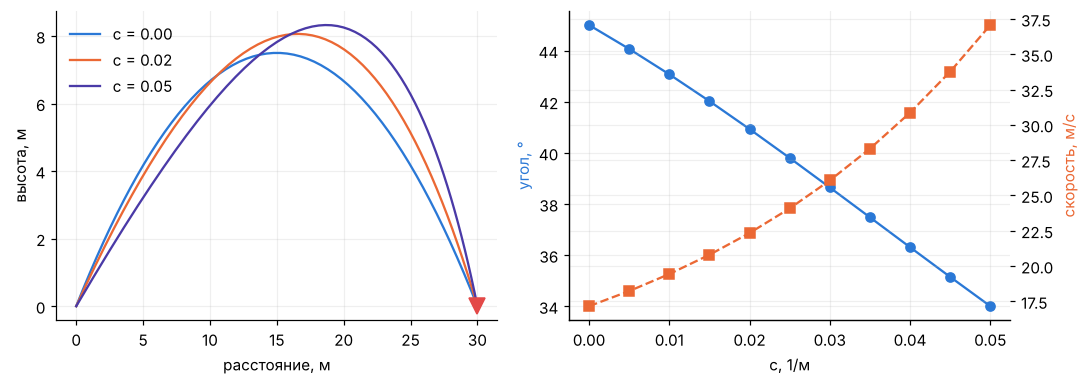

угол при c = 0, 0.02, 0.05: [45.  40.9 34. ]  скорость: [17.2 22.3 37.1]


In [5]:
cs = np.linspace(0, 0.05, 11); angles, speeds, paths = [], [], {}
xs, ls = x_hand, lam_hand
for c in cs:
    xs, ls, _, _, _ = solve_throw(c, xs, ls)                 # старт — ответ при предыдущем c
    angles.append(np.degrees(np.arctan2(xs[1], xs[0]))); speeds.append(np.hypot(xs[0], xs[1]))
    if np.isclose(c, 0) or np.isclose(c, 0.02) or np.isclose(c, 0.05):
        tt = np.linspace(0, xs[2], 60)                       # траектория для картинки
        paths[c] = np.array([[float(v) for v in flight(xs[0], xs[1], t, c, 30)] for t in tt])
assert np.isclose(angles[0], 45) and np.isclose(angles[4], 40.93, atol=0.01)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.6))
for (c, P), col in zip(paths.items(), (BLUE, ORANGE, VIOLET)):
    ax.plot(P[:, 0], P[:, 1], color=col, label=f"c = {c:.2f}")
ax.plot(D, 0, "v", color=RED, ms=10); ax.set_xlabel("расстояние, м"); ax.set_ylabel("высота, м"); ax.legend()
bx.plot(cs, angles, "o-", color=BLUE); bx.set_xlabel("c, 1/м"); bx.set_ylabel("угол, °", color=BLUE)
bx2 = bx.twinx(); bx2.plot(cs, speeds, "s--", color=ORANGE); bx2.set_ylabel("скорость, м/с", color=ORANGE)
plt.tight_layout(); plt.show()
print("угол при c = 0, 0.02, 0.05:", np.round([angles[0], angles[4], angles[-1]], 1), " скорость:", np.round([speeds[0], speeds[4], speeds[-1]], 1))

**Что видим.** Чем сильнее сопротивление, тем ниже угол и больше нужная скорость. Траектория с воздухом несимметрична: спуск круче подъёма.

## Итог

- Без воздуха система из пяти уравнений решается руками: $45^\circ$ и $\sqrt{9.81D}=17.16$ м/с.
- Метод Ньютона–Лагранжа решает её за четыре итерации, не зная формул.
- С сопротивлением воздуха ограничения считает программа, а производные — CasADi. Метод тот же: $40.9^\circ$ и $22.3$ м/с при $c=0.02$ 1/м, как у IPOPT.

**Дома:** упражнения 9.0–9.6. Разбор — [`exercises09.ipynb`](exercises09.ipynb).